# Layer 4: Marketplace Governance & Seller Risk

### Methodology:
1.  **Chronic Offender Identification:** Identifying sellers with high "Seller-side" delays (Preparation Time).
2.  **The "Platform Health" Simulation:** Removing the bottom 5% of worst-performing sellers to calculate global satisfaction improvement.
3.  **Governance Policy: The "2-Day Prep Rule":** Simulating the impact of enforcing a strict 48-hour preparation limit.
4.  **Economic Governance: Risk-Adjusted Commissions:** Proposing a model where high-risk sellers pay for the customer recovery vouchers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Data
df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')

print(f"Reviews loaded: {df.shape}")

Reviews loaded: (95353, 40)


## 1. Chronic Offender Identification

We isolate "Seller-side" responsibility by calculating each seller's average **Preparation Time** and **Bad Review Rate**.

Identified 248 High-Risk Sellers out of 768 active sellers.


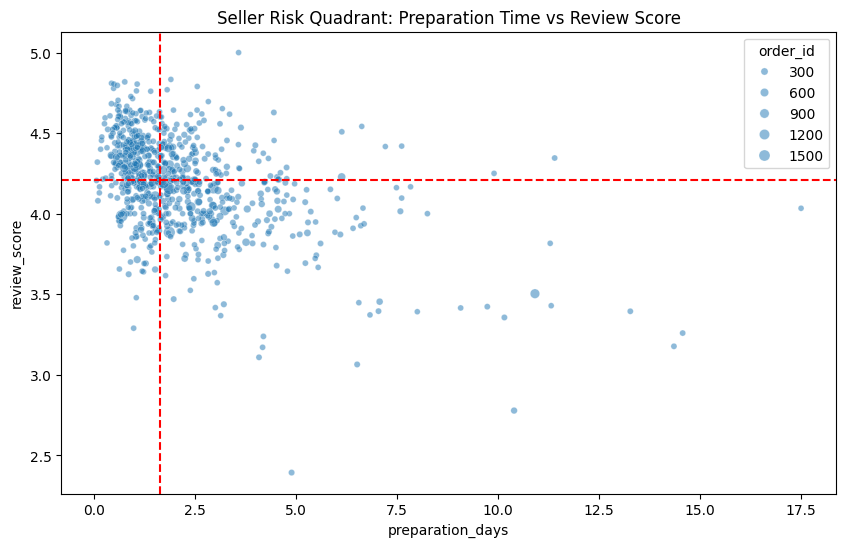

In [2]:
seller_stats = df.groupby('seller_id').agg({
    'preparation_days': 'mean',
    'review_score': 'mean',
    'is_late': 'mean',
    'order_id': 'count'
}).reset_index()

# Filter for active sellers (> 20 orders)
active_sellers = seller_stats[seller_stats['order_id'] > 20]

# Define "High Risk Sellers" as those with above-average prep time and below-average review scores
high_risk_sellers = active_sellers[(
    active_sellers['preparation_days'] > active_sellers['preparation_days'].median()) & 
    (active_sellers['review_score'] < active_sellers['review_score'].median())
]

print(f"Identified {len(high_risk_sellers)} High-Risk Sellers out of {len(active_sellers)} active sellers.")
plt.figure(figsize=(10, 6))
sns.scatterplot(x='preparation_days', y='review_score', size='order_id', alpha=0.5, data=active_sellers)
plt.axvline(active_sellers['preparation_days'].median(), color='red', linestyle='--')
plt.axhline(active_sellers['review_score'].median(), color='red', linestyle='--')
plt.title('Seller Risk Quadrant: Preparation Time vs Review Score')
plt.show()

## 2. Platform Health Simulation (Offboarding)

If Olist were to remove the worst 5% of sellers (those with the lowest review scores and highest prep times), what happens to the overall platform average?

In [3]:
baseline_avg_score = df['review_score'].mean()
worst_5_percent_sellers = active_sellers.sort_values(['review_score', 'preparation_days'], ascending=[True, False]).head(int(len(active_sellers)*0.05))

# Remove these sellers from the simulation
df_cleaned = df[~df['seller_id'].isin(worst_5_percent_sellers['seller_id'])]
improved_avg_score = df_cleaned['review_score'].mean()

print(f"Baseline Platform Score: {baseline_avg_score:.3f}")
print(f"Improved Score (After Offboarding worst 5%): {improved_avg_score:.3f}")
print(f"Projected Churn Reduction: {((improved_avg_score/baseline_avg_score)-1)*100:.2f}% improvement in customer satisfaction.")

Baseline Platform Score: 4.156
Improved Score (After Offboarding worst 5%): 4.185
Projected Churn Reduction: 0.70% improvement in customer satisfaction.


## 3. Policy Reform: The "2-Day Prep Rule"

We simulate a scenario where Olist enforces a rule: All sellers **must** prepare and handover their packages within 48 hours. If they are late, we simulate how many delays would be avoided.

In [4]:
# Orders where prep time > 2 days
slow_prep_orders = df[df['preparation_days'] > 2]

# If we reduced their prep time to exactly 2 days, would they still be late overall?
df['simulated_total_days'] = df['actual_delivery_days'] - (df['preparation_days'] - 2).clip(lower=0)
df['was_late_now_on_time'] = (df['is_late'] == 1) & (df['simulated_total_days'] <= df['estimated_delivery_days'])

recovery_count = df['was_late_now_on_time'].sum()
print(f"By enforcing a 2-day prep rule, {recovery_count} late orders could have been delivered on time.")
print(f"This represents a {recovery_count / df['is_late'].sum() * 100:.1f}% reduction in total platform delays.")

By enforcing a 2-day prep rule, 1711 late orders could have been delivered on time.
This represents a 24.1% reduction in total platform delays.


## 4. Economic Governance: Risk-Adjusted Commission

We propose a model where Sellers pay a "Governance Fee" based on their delay rate. This fee covers the cost of proactive vouchers for their customers.

Top Sellers Required to pay High Governance Fees (The Liability List):
                             seller_id   is_late  governance_fee_per_order
1528  821fb029fc6e495ca4f08a35d51e53a5  0.347826                  5.217391
2852  f76a3b1349b6df1ee875d1f3fa4340f0  0.347826                  5.217391
1992  ad781527c93d00d89a11eecd9dcad7c1  0.342857                  5.142857
2745  ede0c03645598cdfc63ca8237acbe73d  0.333333                  5.000000
988   54965bbe3e4f07ae045b90b0b8541f52  0.294118                  4.411765
1541  835f0f7810c76831d6c7d24c7a646d4d  0.292683                  4.390244
903   4e5725ba188db8252977a4f0227bd462  0.285714                  4.285714
2760  ef990a83bbea832f36ebe81376335aa8  0.261905                  3.928571
472   2a1348e9addc1af5aaa619b1a3679d6b  0.255319                  3.829787
2191  beadbee30901a7f61d031b6b686095ad  0.253968                  3.809524


C:\Users\Devyansh\AppData\Local\Temp\ipykernel_20284\3925950133.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  active_sellers['governance_fee_per_order'] = active_sellers['is_late'] * 15 # The cost of a voucher (R$15) weighted by their failure rate


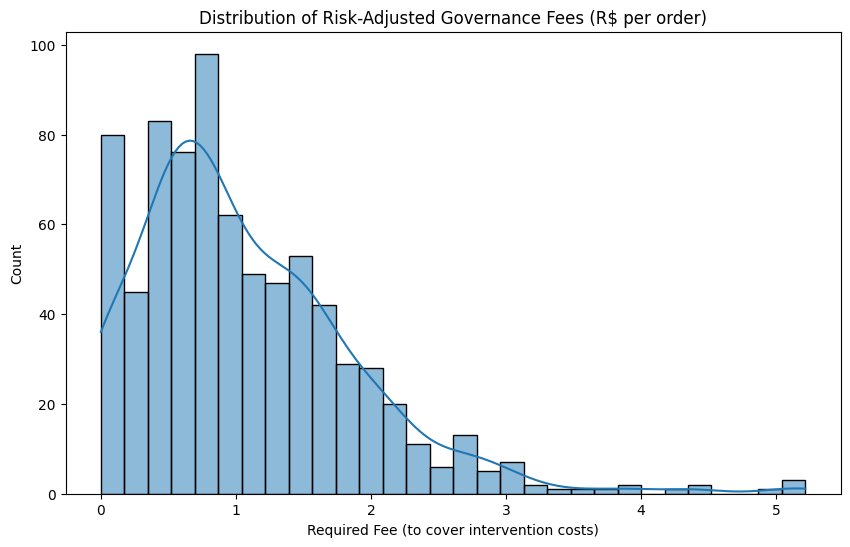

In [5]:
active_sellers['governance_fee_per_order'] = active_sellers['is_late'] * 15 # The cost of a voucher (R$15) weighted by their failure rate

top_fee_sellers = active_sellers.sort_values('governance_fee_per_order', ascending=False).head(10)
print("Top Sellers Required to pay High Governance Fees (The Liability List):")
print(top_fee_sellers[['seller_id', 'is_late', 'governance_fee_per_order']])

plt.figure(figsize=(10, 6))
sns.histplot(active_sellers['governance_fee_per_order'], bins=30, kde=True)
plt.title('Distribution of Risk-Adjusted Governance Fees (R$ per order)')
plt.xlabel('Required Fee (to cover intervention costs)')
plt.show()

### Final Marketplace Insight:
Seller preparation is a major bottleneck that Olist can directly influence through policy (Prep Rules) or economics (Fees). By offboarding only 5% of chronic offenders, Olist improves the overall quality of the platform more effectively than through logistics optimization alone. The **Risk-Adjusted Commission** model shifts the cost of customer dissatisfaction back to the source: the underperforming sellers.